# Strategy 1 - Finding B using regression

In [169]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
from scipy.stats import chi2



In [116]:
# Reading the data 
df = pd.read_csv("Data/price_data.csv", header = 3)
df["Date"] = pd.to_datetime(df['Date'])
df.set_index("Date", inplace=True)
df.head()

/var/folders/nb/jqk45f293z3bx3hy7zrjcv0c0000gn/T/ipykernel_13191/3791631968.py:2: DtypeWarning: Columns (5,64,138,248,268,280,322,355,367,396,447,450,472,509) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("Data/price_data.csv", header = 3)


,Line#,LYB UN,AXP UN,VZ UN,TPL UN,AVGO UW,BA UN,SOLV UN,CAT UN,JPM UN,...,ZTS UN,ARES UN,COIN UW,EQIX UW,DLR UN,MOH UN,LVS UN,Unnamed: 546,Unnamed: 547,Unnamed: 548
Date,,,,,,,,,,,,,,,,,,,,,
2010-07-30,6,NaN,36.08,13.66,7.62,1.56,53.77,NaN,47.87,27.04,...,NaN,NaN,NaN,70.34,34.63,19.87,17.26,NaN,NaN,NaN
2010-08-02,9,NaN,36.36,13.90,7.91,1.57,54.99,NaN,48.76,27.95,...,NaN,NaN,NaN,70.71,35.02,20.33,17.96,NaN,NaN,NaN
2010-08-03,10,NaN,36.05,13.89,7.93,1.55,54.87,NaN,48.30,27.57,...,NaN,NaN,NaN,70.74,34.43,20.69,18.07,NaN,NaN,NaN
2010-08-04,11,NaN,35.65,13.82,8.06,1.60,54.98,NaN,48.81,27.72,...,NaN,NaN,NaN,70.88,34.06,21.14,18.56,NaN,NaN,NaN
2010-08-05,12,NaN,34.93,13.89,8.06,1.63,54.55,NaN,49.39,27.70,...,NaN,NaN,NaN,70.71,33.23,18.87,18.35,NaN,NaN,NaN


<Axes: xlabel='Date'>

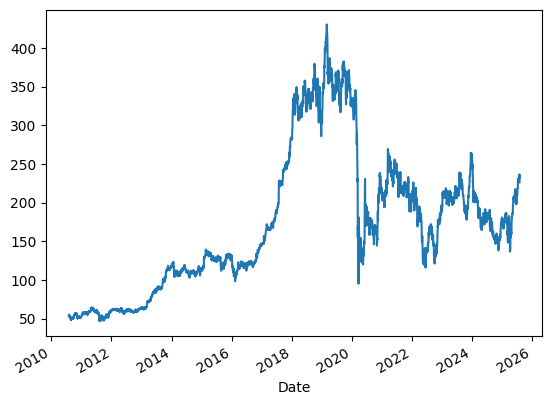

In [158]:
test_stock = df["BA UN"]
test_stock.plot()

/var/folders/nb/jqk45f293z3bx3hy7zrjcv0c0000gn/T/ipykernel_13191/428286594.py:1: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  test_stock.pct_change().dropna().plot()


<Axes: xlabel='Date'>

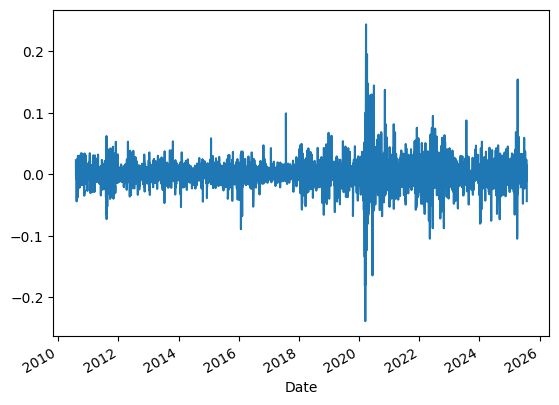

In [118]:
test_stock.pct_change().dropna().plot()

In [119]:
daily_returns = test_stock.pct_change().dropna()
print(daily_returns)

Date
2010-08-02    0.022689
2010-08-03   -0.002182
2010-08-04    0.002005
2010-08-05   -0.007821
2010-08-06   -0.000183
                ...   
2025-07-23    0.023634
2025-07-24   -0.011160
2025-07-25    0.007740
2025-07-28    0.014374
2025-07-29   -0.043695
Name: BA UN, Length: 3772, dtype: float64


/var/folders/nb/jqk45f293z3bx3hy7zrjcv0c0000gn/T/ipykernel_13191/292631666.py:1: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  daily_returns = test_stock.pct_change().dropna()


In [120]:
daily_returns_lagged_1 = daily_returns.shift(1)
print(daily_returns_lagged_1)

Date
2010-08-02         NaN
2010-08-03    0.022689
2010-08-04   -0.002182
2010-08-05    0.002005
2010-08-06   -0.007821
                ...   
2025-07-23   -0.003663
2025-07-24    0.023634
2025-07-25   -0.011160
2025-07-28    0.007740
2025-07-29    0.014374
Name: BA UN, Length: 3772, dtype: float64


In [159]:
print(test_stock)

Date
2010-07-30     53.77
2010-08-02     54.99
2010-08-03     54.87
2010-08-04     54.98
2010-08-05     54.55
               ...  
2025-07-23    233.88
2025-07-24    231.27
2025-07-25    233.06
2025-07-28    236.41
2025-07-29    226.08
Name: BA UN, Length: 3773, dtype: float64


In [161]:
period_prices = test_stock.resample(2).last()
print(period_prices)

ValueError: Invalid frequency: 2

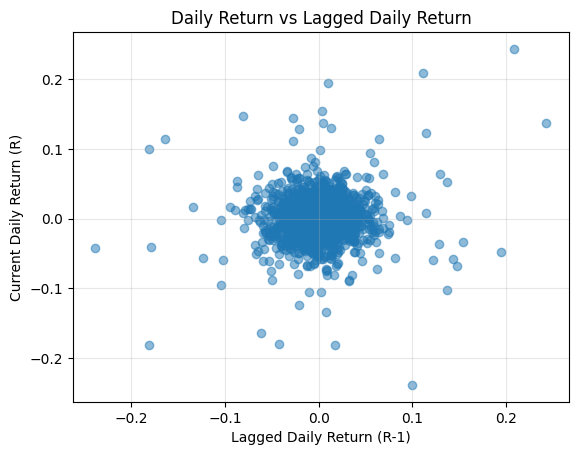

In [121]:
plt.scatter(daily_returns_lagged_1, daily_returns, alpha=0.5)
plt.xlabel("Lagged Daily Return (R-1)")
plt.ylabel("Current Daily Return (R)")
plt.title("Daily Return vs Lagged Daily Return")
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
print(daily_returns_lagged_1["2010"])

Date
2010-08-03    0.022689
2010-08-04   -0.002182
2010-08-05    0.002005
2010-08-06   -0.007821
2010-08-09   -0.000183
                ...   
2010-12-27    0.006977
2010-12-28   -0.004619
2010-12-29    0.001547
2010-12-30    0.003089
2010-12-31   -0.000770
Name: BA UN, Length: 106, dtype: float64


In [154]:
glm_model = sm.GLM(daily_returns.loc["2011":"2020"], sm.add_constant(daily_returns_lagged_1.loc["2011":"2020"]), family=sm.families.Gaussian()).fit()
print(glm_model.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                  BA UN   No. Observations:                 2518
Model:                            GLM   Df Residuals:                     2516
Model Family:                Gaussian   Df Model:                            1
Link Function:               Identity   Scale:                      0.00050963
Method:                          IRLS   Log-Likelihood:                 5973.6
Date:                Tue, 23 Sep 2025   Deviance:                       1.2822
Time:                        17:14:00   Pearson chi2:                     1.28
No. Iterations:                     3   Pseudo R-squ. (CS):           0.006952
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.000      1.665      0.0

In [157]:
def plot_daily_return_daily_lagged_return(stock, lag):
    daily_returns = stock.pct_change().dropna()
    daily_returns_lagged = daily_returns.shift(lag)
    
    plt.scatter(daily_returns, daily_returns_lagged, alpha=0.5)
    plt.xlabel(f"Lagged Daily Return (R-{lag})")
    plt.ylabel("Current Daily Return (R)")
    plt.title(f"Daily Return vs {lag} Days Lagged Daily Return")
    plt.grid(True, alpha=0.3)
    plt.show()

/var/folders/nb/jqk45f293z3bx3hy7zrjcv0c0000gn/T/ipykernel_13191/746026375.py:2: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  daily_returns = stock.pct_change().dropna()


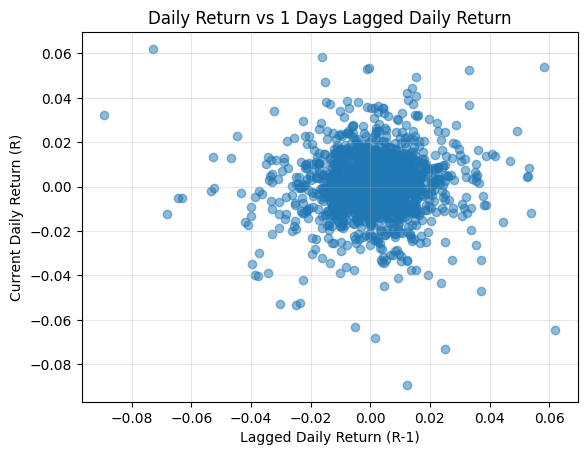

In [162]:
plot_daily_return_daily_lagged_return(test_stock.loc["2011":"2016"], 1)

In [190]:
def plot_deviance_residuals(glm_model):
    residual_deviance = glm_model.resid_deviance
    plt.figure(figsize=(8,4))
    plt.scatter(residual_deviance.index, residual_deviance)
    plt.title("Deviance Residuals")
    plt.show()



def glm_lagged_return(stock, lag):
    daily_returns = stock.pct_change().dropna()
    daily_returns_lagged = daily_returns.shift(lag).dropna()
    daily_returns= daily_returns.iloc[lag:]
    

    glm_model = sm.GLM(daily_returns, sm.add_constant(daily_returns_lagged), family=sm.families.Gaussian()).fit()
    

    print(glm_model.summary())    
    print("Chi squared p-value:", chi2.sf(glm_model.deviance, glm_model.df_resid))
    plot_deviance_residuals(glm_model)
    

    return glm_model
    

                 Generalized Linear Model Regression Results                  
Dep. Variable:                  BA UN   No. Observations:                 1509
Model:                            GLM   Df Residuals:                     1507
Model Family:                Gaussian   Df Model:                            1
Link Function:               Identity   Scale:                      0.00020776
Method:                          IRLS   Log-Likelihood:                 4257.3
Date:                Wed, 24 Sep 2025   Deviance:                      0.31309
Time:                        13:54:30   Pearson chi2:                    0.313
No. Iterations:                     3   Pseudo R-squ. (CS):          0.0008337
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.000      1.992      0.0

/var/folders/nb/jqk45f293z3bx3hy7zrjcv0c0000gn/T/ipykernel_13191/3779120945.py:11: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  daily_returns = stock.pct_change().dropna()


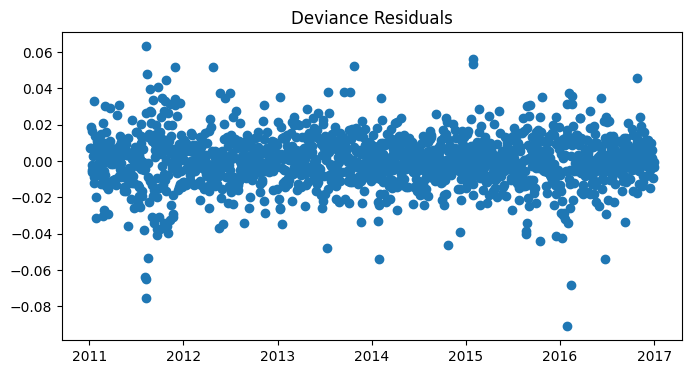

In [191]:
glm_model_1 = glm_lagged_return(test_stock.loc["2011":"2016"], 1)

In [189]:
print(glm_model_1.deviance)

0.3130907411776933


<Axes: xlabel='Date'>

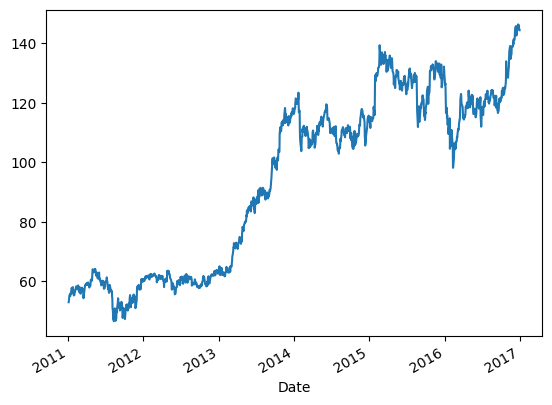

In [164]:
test_stock["2011":"2016"].plot()